# Agrupamento (clustering) das agências do governo dos EUA pelo orçamento

**Disciplina:** IA / Machine Learning - Aprendizado não supervisionado
**Mini projeto em pares** - Integrantes: _Emili Vieira Tabuti_ e _(nome do colega)_

## 1. Objetivo

Usar **aprendizado não supervisionado** para descobrir grupos de agências do governo federal americano que tiveram um comportamento parecido de orçamento ao longo de 40 anos, sem dizer ao algoritmo quais grupos existem.

- **Dataset (Kaggle):** [US Federal Government Budget 1976-2022](https://www.kaggle.com/datasets/mfaaris/usa-budget-authority-by-agency-19762022), de M Faarisul Ilmi (licença PDDL)
- **Origem dos dados:** Office of Management and Budget (OMB), *Budget Authority by Agency*, orçamento do presidente de 2018
- **Conteúdo:** uma linha por **ano** (1976 a 2022) e uma coluna por **agência**; valores em **milhões de dólares** (dólares correntes, sem ajuste de inflação). Os valores a partir de 2017 são **estimativas**
- **Modelo:** **K-Means**, conforme a [documentação do scikit-learn](https://scikit-learn.org/stable/modules/clustering.html)

O arquivo `budget.csv` baixado do Kaggle está em `data/`.

## 2. Importando as bibliotecas

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 3. Carregando os dados

In [2]:
df = pd.read_csv("data/budget.csv", index_col="Year")

print("Anos x agências:", df.shape)
df.iloc[:, :8].head()

Anos x agências: (47, 32)


,Corps of Engineers,Department of Agriculture,Department of Commerce,Department of Defense,Department of Education,Department of Energy,Department of Health and Human Services,Department of Homeland Security
Year,,,,,,,,
1976,2177,20690,1732,95503,9314,4970,40368,2423
1977,2479,21841,7814,107906,10568,7021,47035,2881
1978,2781,26659,1892,114531,11625,10467,51891,3314
1979,2780,37250,2086,123595,13996,9805,59726,3969
1980,3247,39559,2610,140651,15209,10767,70002,4424


## 4. Análise exploratória (EDA)

### 4.1 Estrutura e qualidade dos dados

In [3]:
df.info(max_cols=5)

<class 'pandas.core.frame.DataFrame'>
Index: 47 entries, 1976 to 2022
Columns: 32 entries, Corps of Engineers to Undistributed Offsetting Receipts
dtypes: float64(1), int64(31)
memory usage: 12.1 KB


In [4]:
print("Período:", df.index.min(), "->", df.index.max(), f"({len(df)} anos) | agências:", df.shape[1])
print("Linhas duplicadas:", int(df.duplicated().sum()))

nulos = df.isna().sum()
nulos = nulos[nulos > 0]
print("\nColunas com valores nulos:")
for col, n in nulos.items():
    print(f"  {col}: {n} nulos, anos {df.index[df[col].isna()].tolist()}")

neg = (df < 0).sum()
neg = neg[neg > 0].sort_values(ascending=False)
print("\nAgências com valores negativos (anos):")
print(neg.to_string())

Período: 1976 -> 2022 (47 anos) | agências: 32
Linhas duplicadas: 0

Colunas com valores nulos:
  Other Independent Agencies (Off-Budget): 9 nulos, anos [1976, 1977, 1978, 1979, 1980, 1981, 1982, 2013, 2015]

Agências com valores negativos (anos):
Undistributed Offsetting Receipts          47
General Services Administration             5
Small Business Administration               3
Other Independent Agencies (Off-Budget)     1


Os dados vêm quase completos: só `Other Independent Agencies (Off-Budget)` tem nulos (a agência não existia em 1976-1982, e faltam 2013 e 2015). Os **valores negativos** aparecem em poucas colunas; o mais importante é `Undistributed Offsetting Receipts`, que é **sempre negativa** porque funciona como um "desconto" no orçamento total, e não como uma agência.

### 4.2 Estatísticas por agência (US$ milhões)

In [5]:
df.describe().T.round(0).sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Department of Health and Human Services,47.0,516735.0,419067.0,40368.0,137920.0,364973.0,873894.0,1457442.0
Social Security Administration (Off-Budget),47.0,470802.0,317725.0,74019.0,209873.0,380267.0,646020.0,1232366.0
Department of Defense,47.0,393768.0,191794.0,95503.0,258026.0,290785.0,595719.0,695646.0
Department of the Treasury,47.0,369162.0,217045.0,45880.0,191082.0,376958.0,476269.0,896975.0
Department of Agriculture,47.0,85061.0,40356.0,20690.0,57767.0,69831.0,127742.0,168801.0
Department of Veterans Affairs,47.0,75860.0,62513.0,19013.0,28378.0,44070.0,123414.0,219311.0
Office of Personnel Management,47.0,53997.0,30373.0,8870.0,28732.0,48710.0,76937.0,113839.0
Social Security Administration (On-Budget),47.0,51990.0,42788.0,5991.0,18479.0,39797.0,81076.0,188759.0
Department of Labor,47.0,49138.0,32581.0,16826.0,31226.0,44437.0,51194.0,179228.0
Department of Transportation,47.0,48162.0,24794.0,8456.0,25798.0,46207.0,69044.0,112344.0


### 4.3 Orçamento total ao longo do tempo

A linha tracejada mostra onde terminam os dados reais (2016) e começam as **estimativas** (2017 em diante).

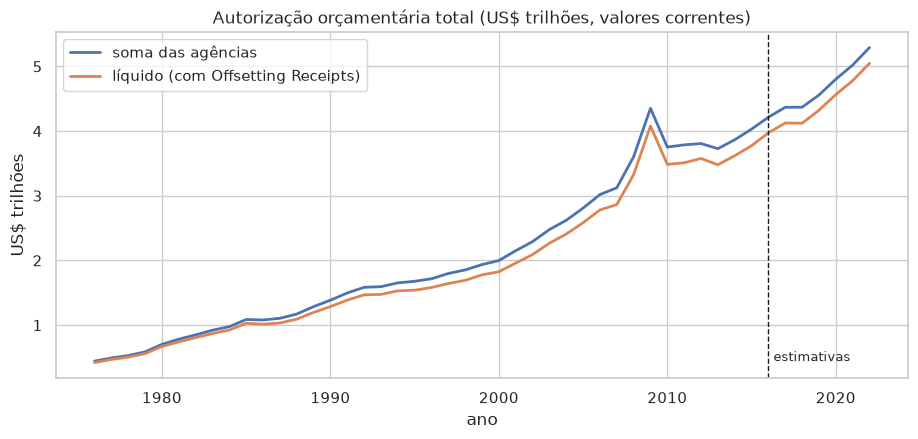

In [6]:
total_liq = df.sum(axis=1) / 1e6                                  # milhões -> trilhões
total_ag = df.drop(columns="Undistributed Offsetting Receipts").sum(axis=1) / 1e6

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(total_ag.index, total_ag, lw=2, label="soma das agências")
ax.plot(total_liq.index, total_liq, lw=2, label="líquido (com Offsetting Receipts)")
ax.axvline(2016, color="k", ls="--", lw=1)
ax.text(2016.3, total_ag.min(), "estimativas", fontsize=9)
ax.set_title("Autorização orçamentária total (US$ trilhões, valores correntes)")
ax.set_xlabel("ano"); ax.set_ylabel("US$ trilhões")
ax.legend()
plt.show()

### 4.4 Quais agências concentram o orçamento?

Existe uma enorme diferença de tamanho entre elas, então usamos escala logarítmica no gráfico de barras.

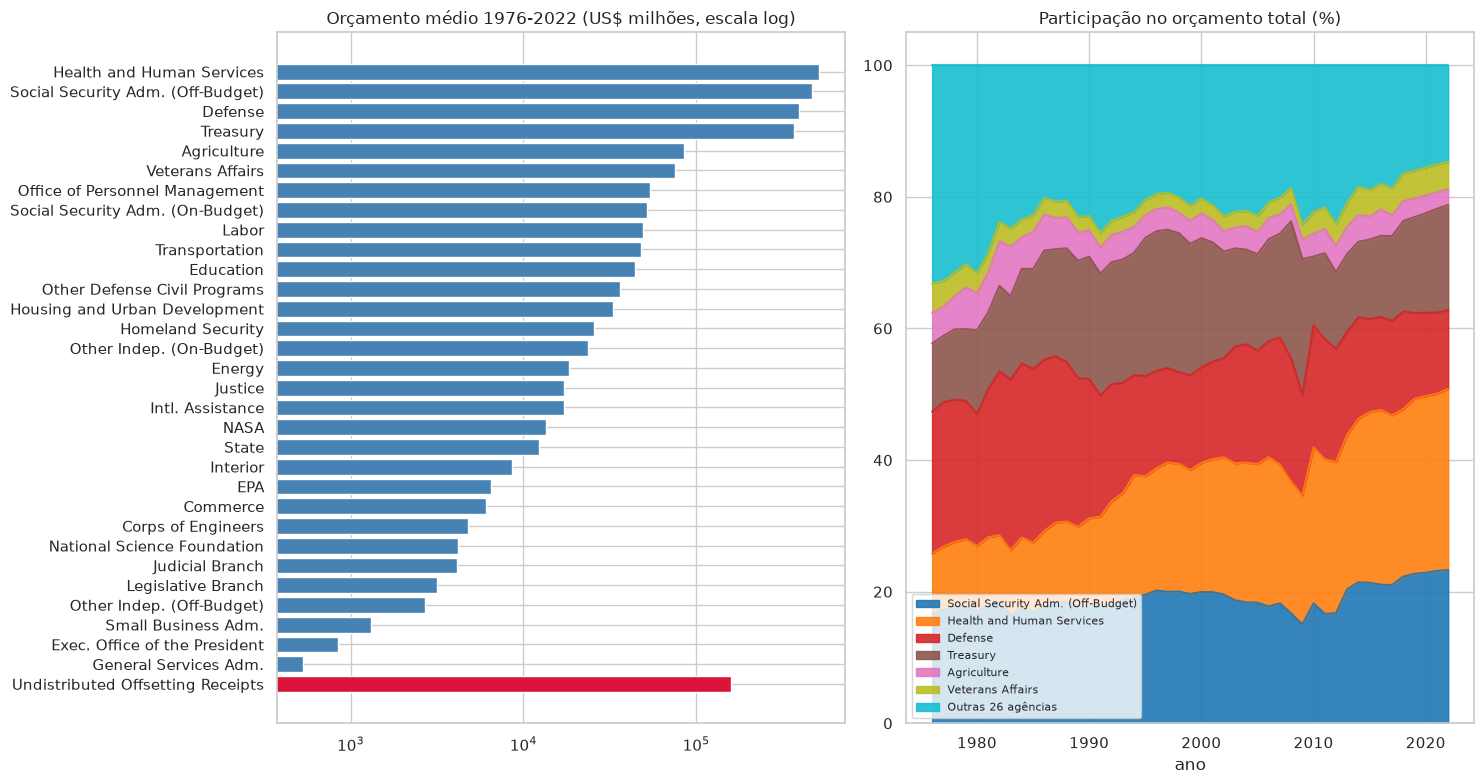

In [7]:
def curto(nome):
    return (nome.replace("Department of the ", "").replace("Department of ", "")
                .replace("Administration", "Adm.").replace("Environmental Protection Agency", "EPA")
                .replace("National Aeronautics and Space Adm.", "NASA")
                .replace("Other Independent Agencies", "Other Indep.")
                .replace("Executive Office of the President", "Exec. Office of the President")
                .replace("International Assistance Programs", "Intl. Assistance"))

media = df.mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].barh([curto(n) for n in media.index], media.abs(), color=np.where(media < 0, "crimson", "steelblue"))
axes[0].set_xscale("log")
axes[0].set_title("Orçamento médio 1976-2022 (US$ milhões, escala log)")

part = df.drop(columns="Undistributed Offsetting Receipts")
part = part.div(part.sum(axis=1), axis=0) * 100
top6 = part.mean().nlargest(6).index
outras = part.drop(columns=top6).sum(axis=1).rename("Outras 26 agências")
pd.concat([part[top6].rename(columns=curto), outras], axis=1).plot.area(ax=axes[1], cmap="tab10", alpha=0.9)
axes[1].set_title("Participação no orçamento total (%)")
axes[1].set_xlabel("ano"); axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

Só **6 agências** respondem por cerca de **78%** do orçamento médio (Previdência fora do orçamento, Saúde, Defesa, Tesouro, Agricultura e Veteranos), e a participação delas mudou bastante entre 1976 e 2016: a **Defesa caiu de 22% para 14%** e a **Saúde (HHS) subiu de 9% para 27%**. Em vermelho está `Undistributed Offsetting Receipts`, em valor absoluto.

### 4.5 Formato da série de cada agência

Para comparar o **formato** independente do tamanho, dividimos cada agência pela sua própria média (1 = igual à média). Dá para ver agências que crescem de forma contínua e outras que oscilam ou têm picos.

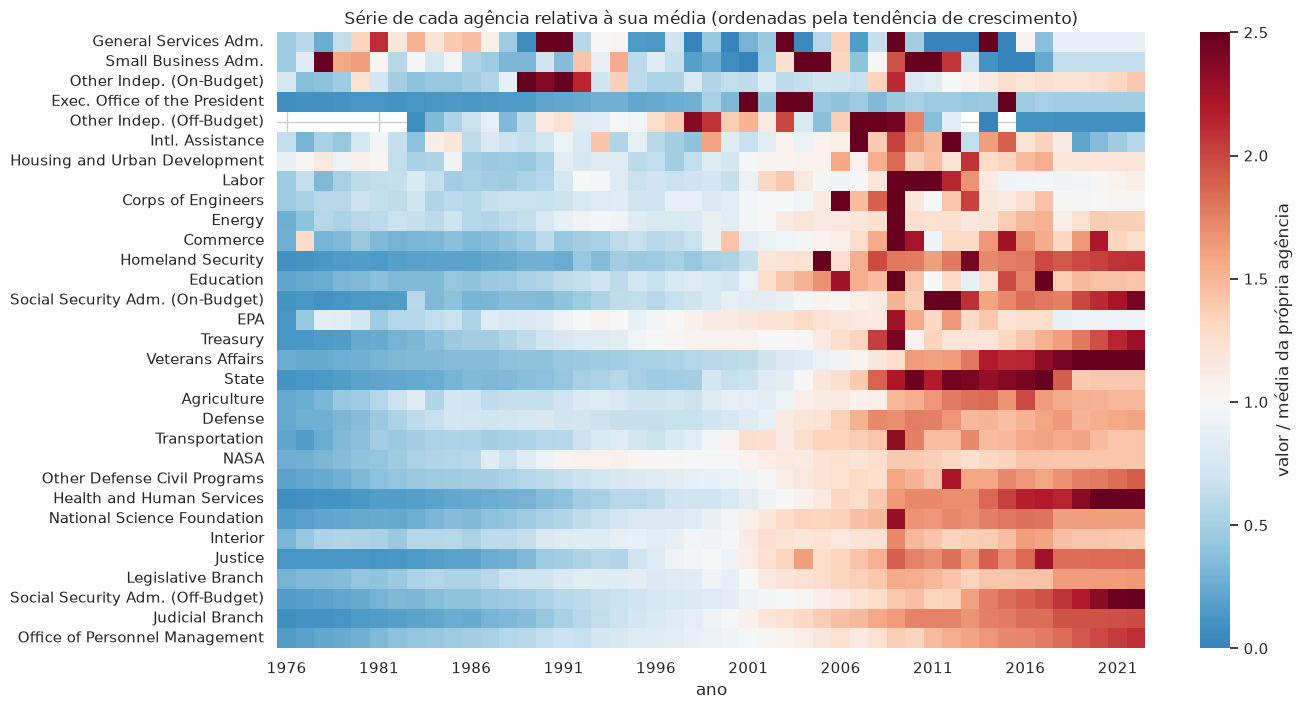

In [8]:
rel = df.drop(columns="Undistributed Offsetting Receipts")
rel = (rel / rel.mean()).T
rel.index = [curto(n) for n in rel.index]
tend = rel.loc[:, 1976:2016].apply(lambda r: r.dropna().corr(pd.Series(r.dropna().index, index=r.dropna().index, dtype=float)), axis=1)
rel = rel.loc[tend.sort_values().index]

plt.figure(figsize=(14, 8))
sns.heatmap(rel, cmap="RdBu_r", center=1, vmin=0, vmax=2.5, cbar_kws={"label": "valor / média da própria agência"},
            xticklabels=5)
plt.title("Série de cada agência relativa à sua média (ordenadas pela tendência de crescimento)")
plt.xlabel("ano"); plt.ylabel("")
plt.show()

## 5. Preparação dos dados para o clustering

O objetivo é agrupar as **agências**, então cada agência vira **uma linha** com características que resumem a série dela. Escolhas feitas:

- **Retirar `Undistributed Offsetting Receipts`:** não é uma agência, é um ajuste contábil negativo, e distorceria os grupos.
- **Usar só 1976-2016:** de 2017 em diante os valores são estimativas.

| Característica | O que representa |
|---|---|
| `log_media` | tamanho médio do orçamento (log10, US$ milhões) |
| `crescimento` | log10 da média de 2012-2016 dividida pela média dos 5 primeiros anos (1 = cresceu 10x) |
| `log_cv` | log10 do coeficiente de variação (desvio padrão / média): quanto a série oscila |
| `tendencia` | correlação entre o valor e o ano (1 = cresce de forma contínua, 0 = sem tendência) |

In [9]:
dados = df.drop(columns="Undistributed Offsetting Receipts").loc[1976:2016]

def corr_tempo(s):
    s = s.dropna()
    return s.corr(pd.Series(s.index, index=s.index, dtype=float))

inicio = dados.apply(lambda s: s.dropna().iloc[:5].mean())   # 5 primeiros anos disponíveis
fim = dados.loc[2012:2016].mean()

X_df = pd.DataFrame({
    "log_media": np.log10(dados.abs().mean()),
    "crescimento": np.log10(fim.abs()) - np.log10(inicio.abs()),
    "log_cv": np.log10(dados.std() / dados.mean().abs()),
    "tendencia": dados.apply(corr_tempo),
})
X_df.index = [curto(n) for n in X_df.index]
print("Shape:", X_df.shape, "| nulos:", int(X_df.isna().sum().sum()))
X_df.round(2).sort_values("log_media", ascending=False)

Shape: (31, 4) | nulos: 0


,log_media,crescimento,log_cv,tendencia
Health and Human Services,5.61,1.26,-0.10,0.96
Social Security Adm. (Off-Budget),5.58,0.92,-0.22,0.98
Defense,5.56,0.71,-0.30,0.91
Treasury,5.51,0.88,-0.24,0.88
Agriculture,4.89,0.73,-0.30,0.91
Veterans Affairs,4.76,0.88,-0.12,0.88
Labor,4.69,0.43,-0.15,0.62
Office of Personnel Management,4.67,0.87,-0.28,0.99
Transportation,4.65,0.75,-0.26,0.93
Social Security Adm. (On-Budget),4.64,1.25,-0.05,0.82


### 5.1 Distribuição e correlação das características

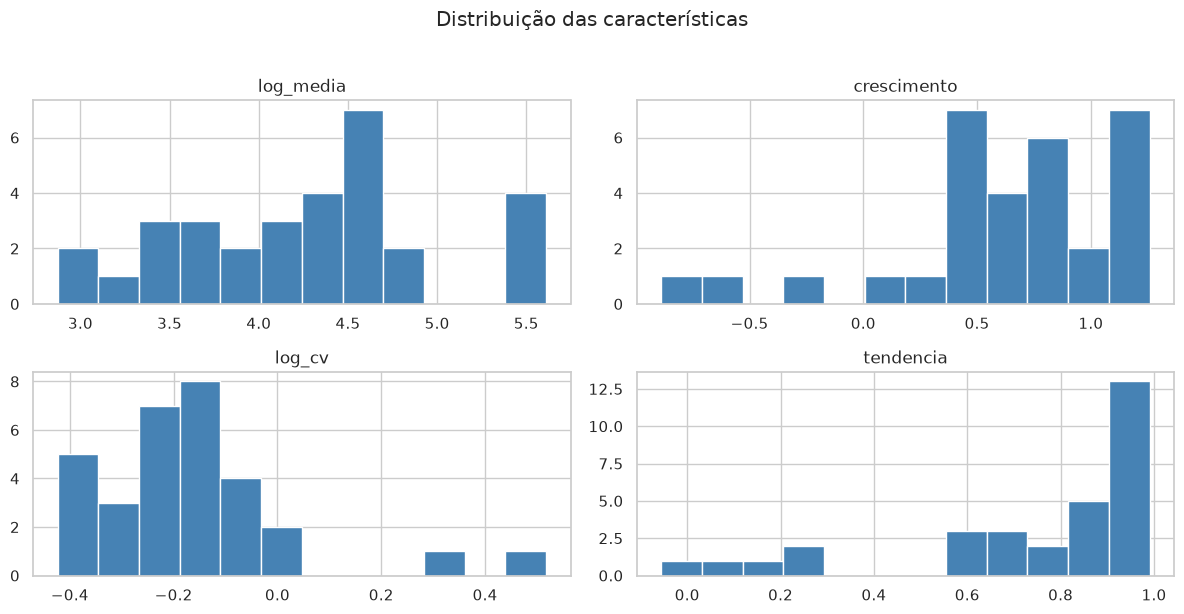

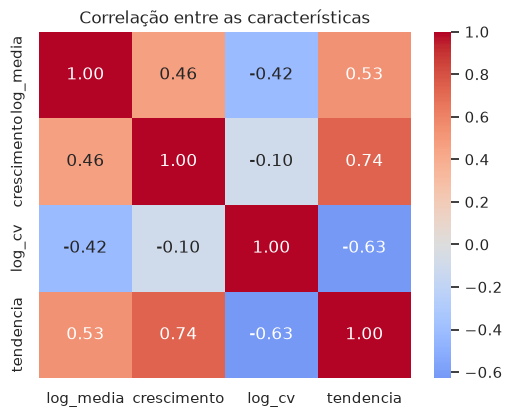

In [10]:
X_df.hist(figsize=(12, 6), bins=12, color="steelblue")
plt.suptitle("Distribuição das características", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4.5))
sns.heatmap(X_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre as características")
plt.show()

As características têm correlações de moderadas a fortes (`crescimento` com `tendencia` = 0,74 e `log_cv` com `tendencia` = -0,63: séries que crescem de forma contínua oscilam menos), mas nenhuma é redundante o bastante para ser descartada. Como as escalas são diferentes, aplicamos **padronização** (`StandardScaler`), pois o K-Means usa distância. Também fazemos um **PCA** só para conseguir visualizar os grupos em 2D.

In [11]:
X = StandardScaler().fit_transform(X_df)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print(f"2 componentes principais explicam {pca.explained_variance_ratio_.sum():.1%} da variância (usados só para visualizar)")

2 componentes principais explicam 84.5% da variância (usados só para visualizar)


## 6. K-Means

### 6.1 Escolhendo o número de clusters (k)

Com apenas 31 agências, testamos k de 2 a 8 e olhamos a inércia (cotovelo), a **silhueta** (maior = melhor) e o índice **Davies-Bouldin** (menor = melhor).

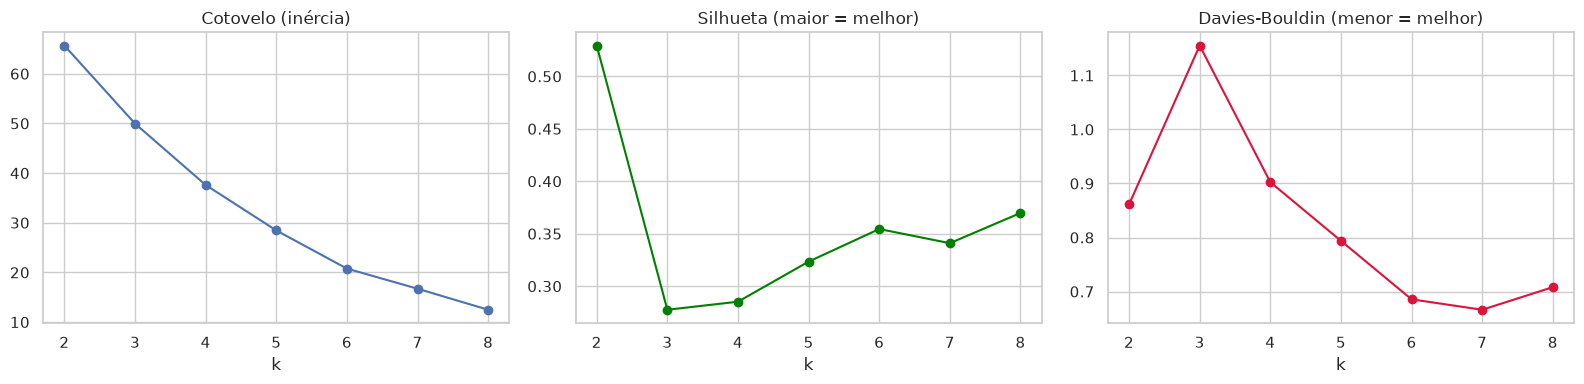

,k,inércia,silhueta,davies_bouldin
0,2,65.674,0.529,0.861
1,3,49.962,0.278,1.155
2,4,37.608,0.285,0.902
3,5,28.448,0.323,0.794
4,6,20.767,0.354,0.686
5,7,16.716,0.341,0.666
6,8,12.478,0.370,0.708


In [12]:
ks = range(2, 9)
inercia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ks, inercia, "o-"); axes[0].set_title("Cotovelo (inércia)")
axes[1].plot(ks, sil, "o-", color="green"); axes[1].set_title("Silhueta (maior = melhor)")
axes[2].plot(ks, dbi, "o-", color="crimson"); axes[2].set_title("Davies-Bouldin (menor = melhor)")
for a in axes: a.set_xlabel("k")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(ks), "inércia": inercia, "silhueta": sil, "davies_bouldin": dbi}).round(3)

A silhueta é maior com k = 2, mas esse resultado é pouco útil (separa só as agências grandes de todas as outras). A partir de k = 5 o Davies-Bouldin melhora bastante e os grupos ficam mais fáceis de explicar, então vamos usar **k = 5**.

### 6.2 Modelo final

In [13]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=100, random_state=RANDOM_STATE).fit(X)
X_df["cluster"] = kmeans.labels_

print(f"k = {K} | silhueta = {silhouette_score(X, kmeans.labels_):.3f} | Davies-Bouldin = {davies_bouldin_score(X, kmeans.labels_):.3f}")
for c in range(K):
    print(f"\nCluster {c} ({(X_df.cluster == c).sum()} agências):")
    print("  " + "; ".join(X_df.index[X_df.cluster == c]))

k = 5 | silhueta = 0.323 | Davies-Bouldin = 0.794

Cluster 0 (6 agências):
  Homeland Security; Justice; State; Judicial Branch; National Science Foundation; Social Security Adm. (On-Budget)

Cluster 1 (10 agências):
  Corps of Engineers; Commerce; Energy; Housing and Urban Development; Labor; Interior; EPA; Intl. Assistance; Legislative Branch; NASA

Cluster 2 (1 agências):
  Exec. Office of the President

Cluster 3 (4 agências):
  General Services Adm.; Other Indep. (Off-Budget); Other Indep. (On-Budget); Small Business Adm.

Cluster 4 (10 agências):
  Agriculture; Defense; Education; Health and Human Services; Treasury; Transportation; Veterans Affairs; Office of Personnel Management; Other Defense Civil Programs; Social Security Adm. (Off-Budget)


### 6.3 Visualização dos clusters (PCA 2D)

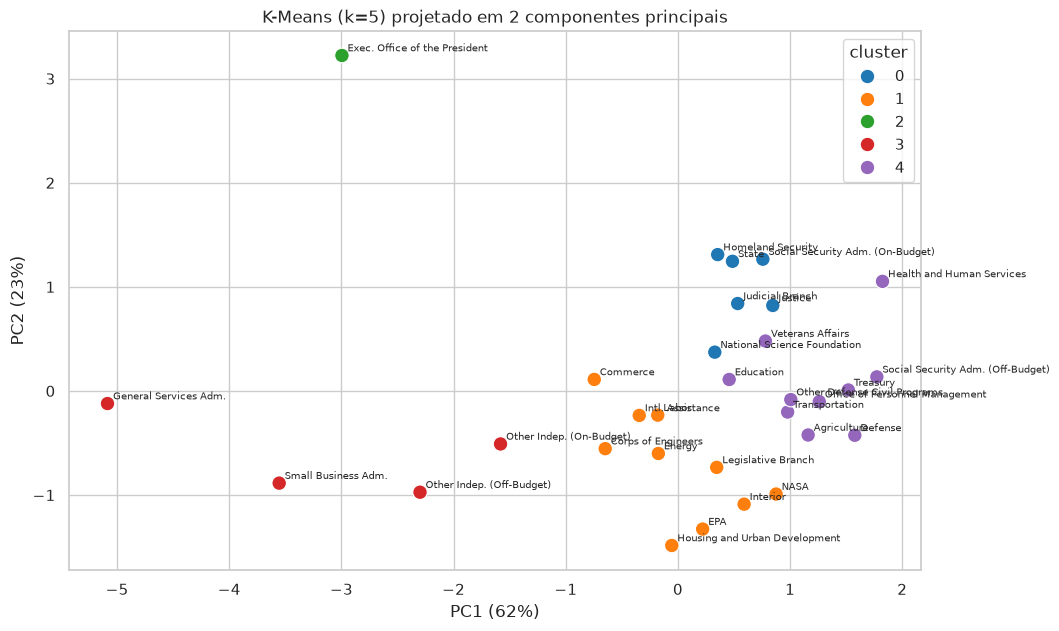

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans.labels_, palette="tab10", s=110, ax=ax)
for (x, y), nome in zip(X_pca, X_df.index):
    ax.annotate(nome, (x, y), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_title(f"K-Means (k={K}) projetado em 2 componentes principais")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(title="cluster")
plt.show()

### 6.4 Perfil de cada cluster

In [15]:
perfil = X_df.groupby("cluster").mean().round(2)
perfil.insert(0, "n_agencias", X_df["cluster"].value_counts().sort_index())
perfil

,n_agencias,log_media,crescimento,log_cv,tendencia
cluster,,,,,
0,6,4.06,1.15,-0.09,0.91
1,10,4.04,0.45,-0.29,0.76
2,1,2.96,1.09,0.52,0.21
3,4,3.47,-0.35,0.02,0.12
4,10,5.03,0.86,-0.22,0.92


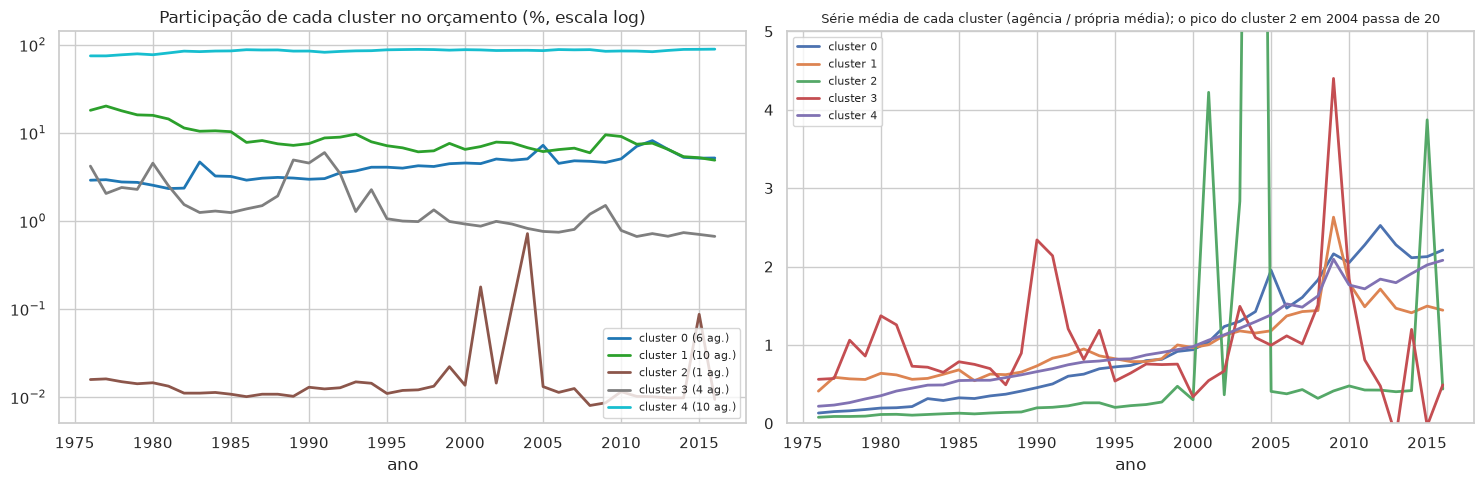

,cluster 0 (6 ag.),cluster 1 (10 ag.),cluster 2 (1 ag.),cluster 3 (4 ag.),cluster 4 (10 ag.)
Year,,,,,
1976,2.9,18.0,0.0,4.2,74.9
1996,4.0,6.8,0.0,1.0,88.3
2016,5.2,4.9,0.0,0.7,89.2


In [16]:
# participação de cada cluster no orçamento total das agências, ano a ano
part_ag = dados.div(dados.sum(axis=1), axis=0) * 100
part_cluster = pd.DataFrame({
    f"cluster {c} ({(X_df.cluster == c).sum()} ag.)": part_ag[[col for col in dados.columns if curto(col) in X_df.index[X_df.cluster == c]]].sum(axis=1)
    for c in range(K)
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
part_cluster.plot(ax=axes[0], logy=True, lw=2, cmap="tab10")
axes[0].set_title("Participação de cada cluster no orçamento (%, escala log)")
axes[0].set_xlabel("ano"); axes[0].legend(fontsize=8)

for c in range(K):
    cols = [col for col in dados.columns if curto(col) in X_df.index[X_df.cluster == c]]
    rel_c = (dados[cols] / dados[cols].mean()).mean(axis=1)
    axes[1].plot(rel_c.index, rel_c, lw=2, label=f"cluster {c}")
axes[1].set_ylim(0, 5)
axes[1].set_title("Série média de cada cluster (agência / própria média); o pico do cluster 2 em 2004 passa de 20")
axes[1].title.set_fontsize(9)
axes[1].set_xlabel("ano"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

part_cluster.loc[[1976, 1996, 2016]].round(1)

### 6.5 Interpretação do K-Means (k = 5)

O K-Means (k = 5, silhueta 0,32 e Davies-Bouldin 0,79) separou as agências em cinco perfis:

| Cluster | Agências | Perfil | Exemplos |
|---|---|---|---|
| **4 - Grandes e estáveis** | 10 | Maiores orçamentos (média ~100 bilhões), crescimento contínuo (tendência 0,92) e pouca oscilação; ficam com **75% a 89%** do total | Defesa, Saúde (HHS), Tesouro, Previdência (off-budget), Agricultura, Veteranos, Educação |
| **0 - Médias de crescimento acelerado** | 6 | Tamanho médio, mas foram as que mais cresceram (~14x entre o começo e o fim do período) de forma contínua; a participação foi de 2,9% para 5,2% | Segurança Interna, Justiça, Estado, Judiciário, National Science Foundation, Previdência (on-budget) |
| **1 - Médias de crescimento lento** | 10 | Tamanho parecido com o cluster 0, mas cresceram só ~2,8x e com tendência mais fraca; perderam participação (de 18% para 4,9%) | Habitação (HUD), Trabalho, Energia, Interior, EPA, NASA, Corpo de Engenheiros, Assistência Internacional |
| **3 - Pequenas e irregulares** | 4 | Orçamento pequeno, sem tendência (0,12) e que em média **encolheu**; alternam picos e valores negativos | GSA, Small Business Administration, Other Independent Agencies (on e off-budget) |
| **2 - Caso isolado** | 1 | Orçamento minúsculo quase sempre (~400 milhões), mas com picos enormes: 18,8 bilhões em 2004 | Executive Office of the President |

O algoritmo separou as agências principalmente por **tamanho** e pelo **jeito de crescer** (contínuo, lento ou irregular), sem usar o nome nem a função de cada uma. O cluster 2 com uma agência só mostra que ela é um *outlier* bem claro: o K-Means prefere isolar um ponto muito distante do que misturá-lo com os outros.

## 7. Conclusões

- O **K-Means com k = 5** agrupou as 31 agências em perfis que fazem sentido: as grandes e estáveis (75-89% do orçamento), as médias de crescimento rápido, as médias de crescimento lento, as pequenas e irregulares, e uma agência isolada por causa dos picos.
- A **silhueta de 0,32 é moderada**: as agências formam mais um *contínuo* de tamanhos e ritmos de crescimento do que grupos bem separados. A silhueta é maior com k = 2 (0,53), mas isso só separa as grandes das demais, o que não ajuda a interpretar.
- **Limitações:** são só 31 agências (qualquer mudança nas características pode mover algumas delas de grupo); os valores estão em **dólares correntes**, então parte do crescimento é inflação; o dataset é de *budget authority* (autorização), não de gastos efetivos; e `Undistributed Offsetting Receipts` e os anos de estimativa (2017-2022) ficaram fora.
- **Próximos passos:** corrigir os valores pela inflação, testar outros algoritmos (Affinity Propagation, DBSCAN) e também agrupar os **anos** (em vez das agências) para ver "eras" do orçamento.

### Referências
- Dataset no Kaggle: https://www.kaggle.com/datasets/mfaaris/usa-budget-authority-by-agency-19762022
- scikit-learn, *Clustering*: https://scikit-learn.org/stable/modules/clustering.html